# 5층 · 생성형 AI 실습

프롬프트를 AI에게 보내 받은 파이썬 코드입니다. 위에서부터 셀을 차례로 실행해 보세요.
데이터는 GitHub 저장소에서 바로 불러옵니다.

저장된 결과는 Python 3.13.18 · pandas 3.0.5 · scikit-learn 1.9.1 · NumPy 2.5.3 · matplotlib 3.11.2 로 실행한 것입니다. Colab에서는 라이브러리 버전에 따라 소수점이 조금 다를 수 있습니다.

## 실습 1 · 질문 나무가 만든 규칙 읽기

**프롬프트**

> fish_bream_smelt.csv로 깊이 2짜리 의사결정나무를 만들어 주세요.
> 나무가 고른 질문을 글(규칙)로 출력하고, 나무 그림도 그려 주세요.

|--- weight <= 130.95
|   |--- class: smelt
|--- weight >  130.95
|   |--- class: bream

학습 데이터 정확도: 1.0


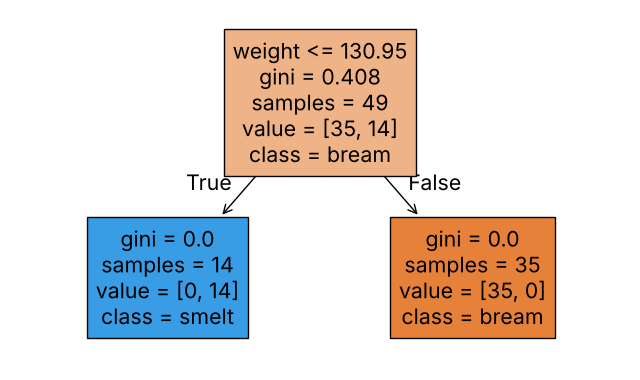

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

fish = pd.read_csv("https://raw.githubusercontent.com/adminmrobo/python_machine_learning_lab/main/data/fish_bream_smelt.csv")
X, y = fish[["length", "weight"]], fish["species"]

tree = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X, y)
print(export_text(tree, feature_names=["length", "weight"]))
print("학습 데이터 정확도:", tree.score(X, y))

plot_tree(tree, feature_names=["length", "weight"], class_names=list(tree.classes_), filled=True)
plt.show()

**박사의 한 줄 판단** — 깊이 2를 허락했지만 나무는 ‘무게 130.95g 이하인가?’ 질문 하나로 끝냈습니다. 학습 정확도 1.0은 이 쉬운 짝에서는 어떤 모델도 받는 점수라, 어려운 짝으로 다시 확인해야 합니다.

## 실습 2 · 나누는 약속 — 순서대로 자르기 vs 비율 맞추기

**프롬프트**

> fish_bream_smelt.csv는 도미 35마리 다음에 빙어 14마리가 차례로 들어 있어요.
> ① 앞 35마리로 학습, 뒤 14마리로 시험
> ② train_test_split(stratify=...)로 비율 맞춰 나누기
> 두 방법의 k-NN 시험 정확도와 시험용 종류 수를 비교해 주세요.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

fish = pd.read_csv("https://raw.githubusercontent.com/adminmrobo/python_machine_learning_lab/main/data/fish_bream_smelt.csv")
X, y = fish[["length", "weight"]], fish["species"]

# ① 순서대로 자르기
kn = KNeighborsClassifier().fit(X[:35], y[:35])
print("① 순서대로 → 시험 정확도:", kn.score(X[35:], y[35:]), "/ 시험용:", y[35:].value_counts().to_dict())

# ② 비율 맞춰 나누기
X_tr, X_te, y_tr, y_te = train_test_split(X, y, stratify=y, random_state=42)
kn = KNeighborsClassifier().fit(X_tr, y_tr)
print("② 비율 맞춤 → 시험 정확도:", kn.score(X_te, y_te), "/ 시험용:", y_te.value_counts().to_dict())

① 순서대로 → 시험 정확도: 0.0 / 시험용: {'smelt': 14}
② 비율 맞춤 → 시험 정확도: 1.0 / 시험용: {'bream': 9, 'smelt': 4}


**박사의 한 줄 판단** — 순서대로 자르면 시험용 14마리가 모두 빙어라 정확도 0.0, 비율 맞춰 나누면 1.0입니다. 모델은 같은데 나누는 방법만으로 점수가 끝과 끝으로 갈렸어요.